# Exploratory Data Analysis (EDA)

## Milestone 6: EDA

This notebook performs exploratory data analysis on the telecom customer intelligence dataset to understand:
- Customer demographics and distributions
- Usage patterns and trends
- Churn patterns and correlations
- Outliers and anomalies

**Data Source:** CSV files (customer_info_db2.csv, usage_data_db2.csv, churn_labels_db2.csv)

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print('Libraries imported successfully')

Libraries imported successfully


## 1. Load Data from CSV Files

In [37]:
# Load data from CSV files
customers_df = pd.read_csv(r"D:\Ahmed\My Projects\telecom intelligence project\data\processed\customer_info_db2.csv")
usage_df = pd.read_csv(r"D:\Ahmed\My Projects\telecom intelligence project\data\processed\usage_data_db2.csv")
churn_df = pd.read_csv(r"D:\Ahmed\My Projects\telecom intelligence project\data\processed\churn_labels_db2.csv")

print(f"Customers loaded: {len(customers_df)} rows")
print(f"Columns: {customers_df.columns.tolist()}")

print(f"\nUsage records loaded: {len(usage_df)} rows")
print(f"Columns: {usage_df.columns.tolist()}")

print(f"\nChurn labels loaded: {len(churn_df)} rows")
print(f"Columns: {churn_df.columns.tolist()}")

# Merge churn labels with customers
customers_df = customers_df.merge(churn_df, on='customer_id', how='left')

# Merge usage with customer demographics and churn
usage_df = usage_df.merge(customers_df[['customer_id', 'age', 'gender', 'region', 'contract_type', 'monthly_charges', 'churn']], 
                         on='customer_id', how='left')

print(f"\nCustomers after merge: {len(customers_df)} rows")
print(f"Usage after merge: {len(usage_df)} rows")

# Display first few rows
print("\nCustomers sample:")
print(customers_df.head())

print("\nUsage sample:")
print(usage_df.head())

Customers loaded: 10000 rows
Columns: ['customer_id', 'age', 'gender', 'region', 'contract_type', 'monthly_charges', 'signup_date']

Usage records loaded: 120060 rows
Columns: ['customer_id', 'month', 'call_minutes', 'data_usage_gb', 'sms_count', 'complaints']

Churn labels loaded: 10000 rows
Columns: ['customer_id', 'churn']

Customers after merge: 10000 rows
Usage after merge: 120060 rows

Customers sample:
  customer_id   age  gender    region contract_type  monthly_charges  \
0      CUST_0  42.0    Male     Urban        Yearly            48.18   
1      CUST_1  44.0  Female  Suburban       Prepaid            38.94   
2     CUST_10  43.0  Female     Urban       Prepaid            47.81   
3    CUST_100  62.0  Female     Urban       Monthly            29.80   
4   CUST_1000  44.0  Female  Suburban       Monthly            61.62   

  signup_date  churn  
0  2021-03-20      0  
1  2020-01-25      0  
2  2022-04-29      0  
3  2021-10-14      0  
4  2018-06-10      0  

Usage sample:
 

## 2. Data Quality Checks

In [38]:
# Check for missing values
print("Missing values in customers_df:")
print(customers_df.isnull().sum())

print("\nMissing values in usage_df:")
print(usage_df.isnull().sum())

print("\nMissing values in churn_df:")
print(churn_df.isnull().sum())

# Check data types
print("\nData types - customers_df:")
print(customers_df.dtypes)

print("\nData types - usage_df:")
print(usage_df.dtypes)

# Basic statistics
print("\nCustomers summary statistics:")
print(customers_df.describe())

print("\nUsage summary statistics:")
print(usage_df.describe())

Missing values in customers_df:
customer_id        0
age                0
gender             0
region             0
contract_type      0
monthly_charges    0
signup_date        0
churn              0
dtype: int64

Missing values in usage_df:
customer_id        0
month              0
call_minutes       0
data_usage_gb      0
sms_count          0
complaints         0
age                0
gender             0
region             0
contract_type      0
monthly_charges    0
churn              0
dtype: int64

Missing values in churn_df:
customer_id    0
churn          0
dtype: int64

Data types - customers_df:
customer_id            str
age                float64
gender                 str
region                 str
contract_type          str
monthly_charges    float64
signup_date            str
churn                int64
dtype: object

Data types - usage_df:
customer_id            str
month                int64
call_minutes       float64
data_usage_gb      float64
sms_count            int64


## 3. Customer Demographics Analysis

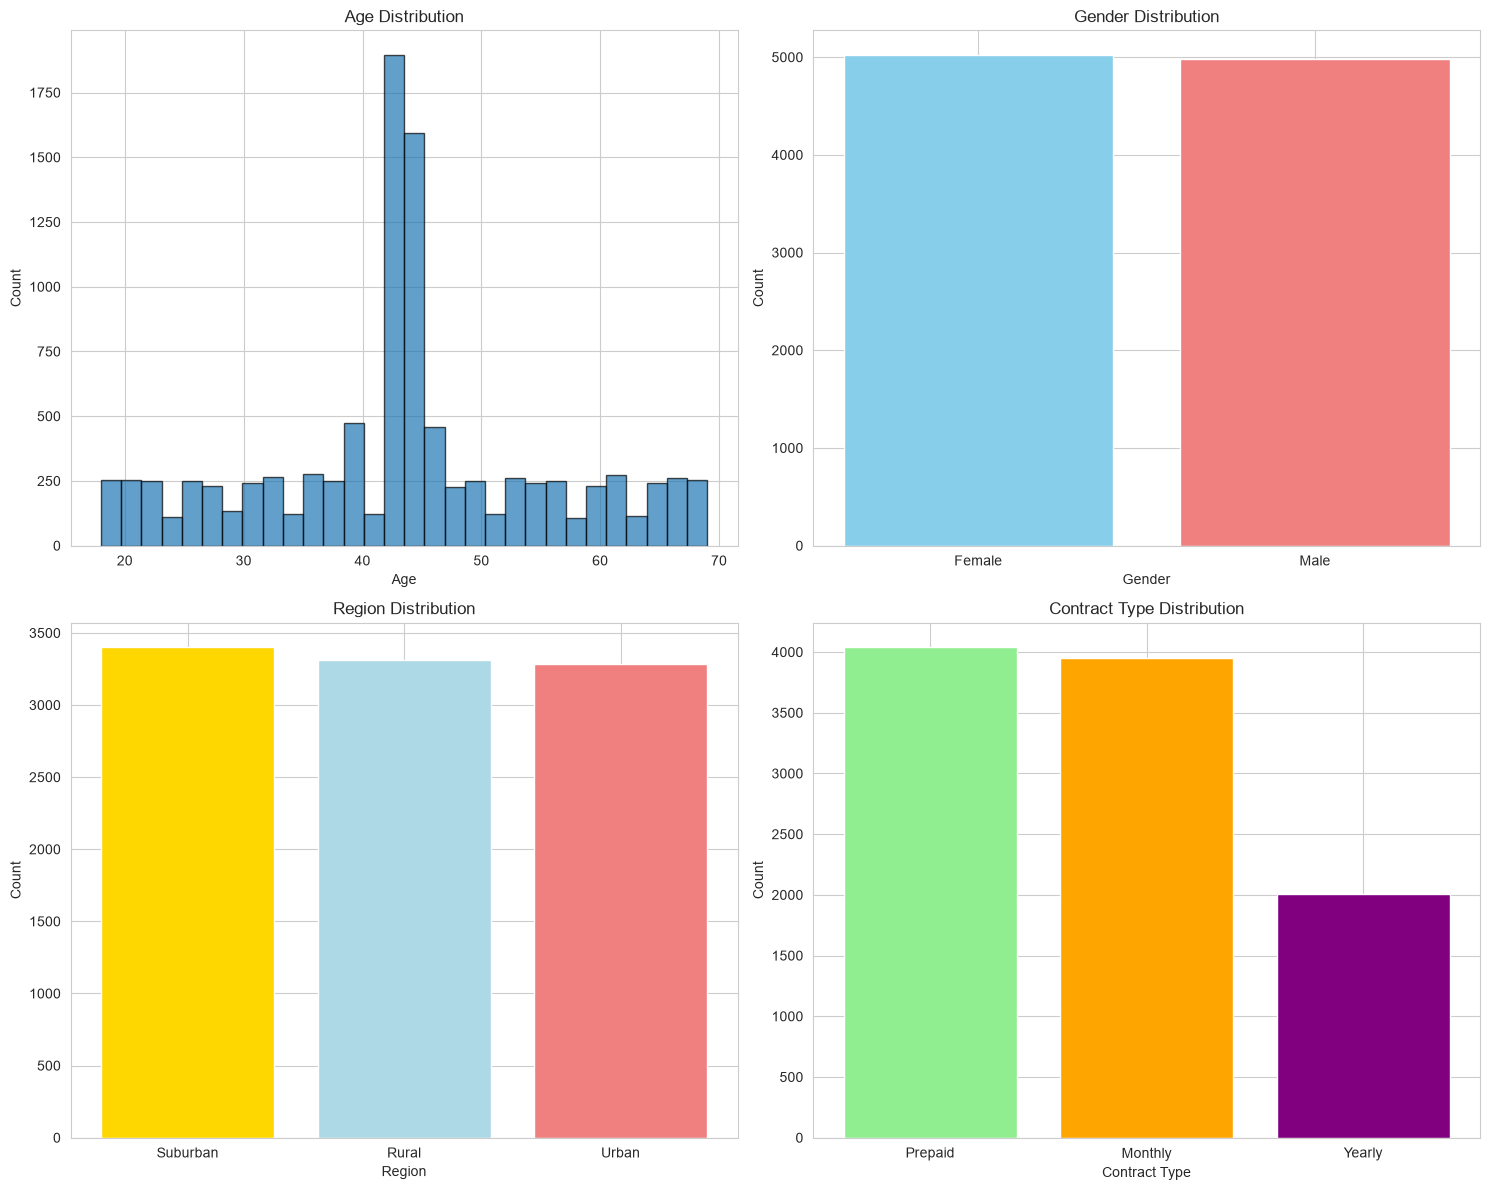


Age Statistics:
Mean: 43.36
Median: 43.00
Std: 12.10
Min: 18.0
Max: 69.0

Gender Distribution:
gender
Female    50.22
Male      49.78
Name: proportion, dtype: float64

Region Distribution:
region
Suburban    34.02
Rural       33.11
Urban       32.87
Name: proportion, dtype: float64

Contract Type Distribution:
contract_type
Prepaid    40.41
Monthly    39.53
Yearly     20.06
Name: proportion, dtype: float64


In [39]:
# Age distribution
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Age distribution
axes[0, 0].hist(customers_df['age'], bins=30, edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Age Distribution')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Count')

# Gender distribution
gender_counts = customers_df['gender'].value_counts()
axes[0, 1].bar(gender_counts.index, gender_counts.values, color=['skyblue', 'lightcoral', 'lightgreen'])
axes[0, 1].set_title('Gender Distribution')
axes[0, 1].set_xlabel('Gender')
axes[0, 1].set_ylabel('Count')

# Region distribution
region_counts = customers_df['region'].value_counts()
axes[1, 0].bar(region_counts.index, region_counts.values, color=['gold', 'lightblue', 'lightcoral'])
axes[1, 0].set_title('Region Distribution')
axes[1, 0].set_xlabel('Region')
axes[1, 0].set_ylabel('Count')

# Contract type distribution
contract_counts = customers_df['contract_type'].value_counts()
axes[1, 1].bar(contract_counts.index, contract_counts.values, color=['lightgreen', 'orange', 'purple'])
axes[1, 1].set_title('Contract Type Distribution')
axes[1, 1].set_xlabel('Contract Type')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Print statistics
print("\nAge Statistics:")
print(f"Mean: {customers_df['age'].mean():.2f}")
print(f"Median: {customers_df['age'].median():.2f}")
print(f"Std: {customers_df['age'].std():.2f}")
print(f"Min: {customers_df['age'].min()}")
print(f"Max: {customers_df['age'].max()}")

print("\nGender Distribution:")
print(customers_df['gender'].value_counts(normalize=True).mul(100).round(2))

print("\nRegion Distribution:")
print(customers_df['region'].value_counts(normalize=True).mul(100).round(2))

print("\nContract Type Distribution:")
print(customers_df['contract_type'].value_counts(normalize=True).mul(100).round(2))

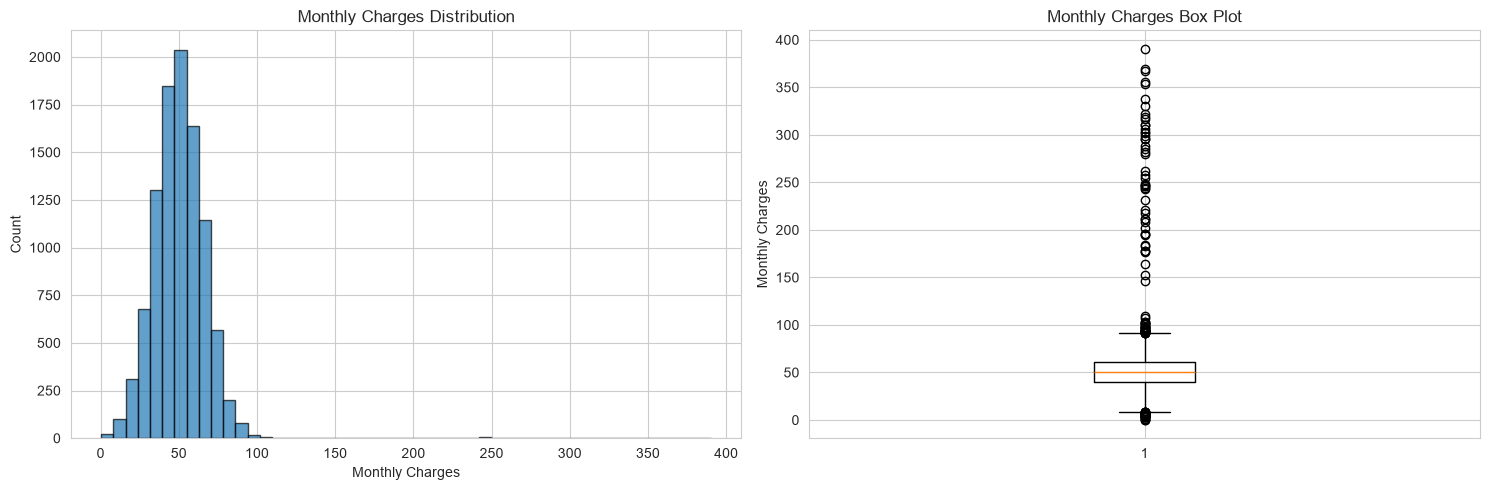


Monthly Charges Statistics:
Mean: 51.00
Median: 50.02
Std: 21.53
Min: 0.38
Max: 390.30
25th percentile: 39.80
75th percentile: 60.50


In [40]:
# Monthly charges distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(customers_df['monthly_charges'], bins=50, edgecolor='black', alpha=0.7)
axes[0].set_title('Monthly Charges Distribution')
axes[0].set_xlabel('Monthly Charges')
axes[0].set_ylabel('Count')

# Box plot for monthly charges
axes[1].boxplot(customers_df['monthly_charges'])
axes[1].set_title('Monthly Charges Box Plot')
axes[1].set_ylabel('Monthly Charges')

plt.tight_layout()
plt.show()

print("\nMonthly Charges Statistics:")
print(f"Mean: {customers_df['monthly_charges'].mean():.2f}")
print(f"Median: {customers_df['monthly_charges'].median():.2f}")
print(f"Std: {customers_df['monthly_charges'].std():.2f}")
print(f"Min: {customers_df['monthly_charges'].min():.2f}")
print(f"Max: {customers_df['monthly_charges'].max():.2f}")
print(f"25th percentile: {customers_df['monthly_charges'].quantile(0.25):.2f}")
print(f"75th percentile: {customers_df['monthly_charges'].quantile(0.75):.2f}")

## 4. Usage Patterns Analysis

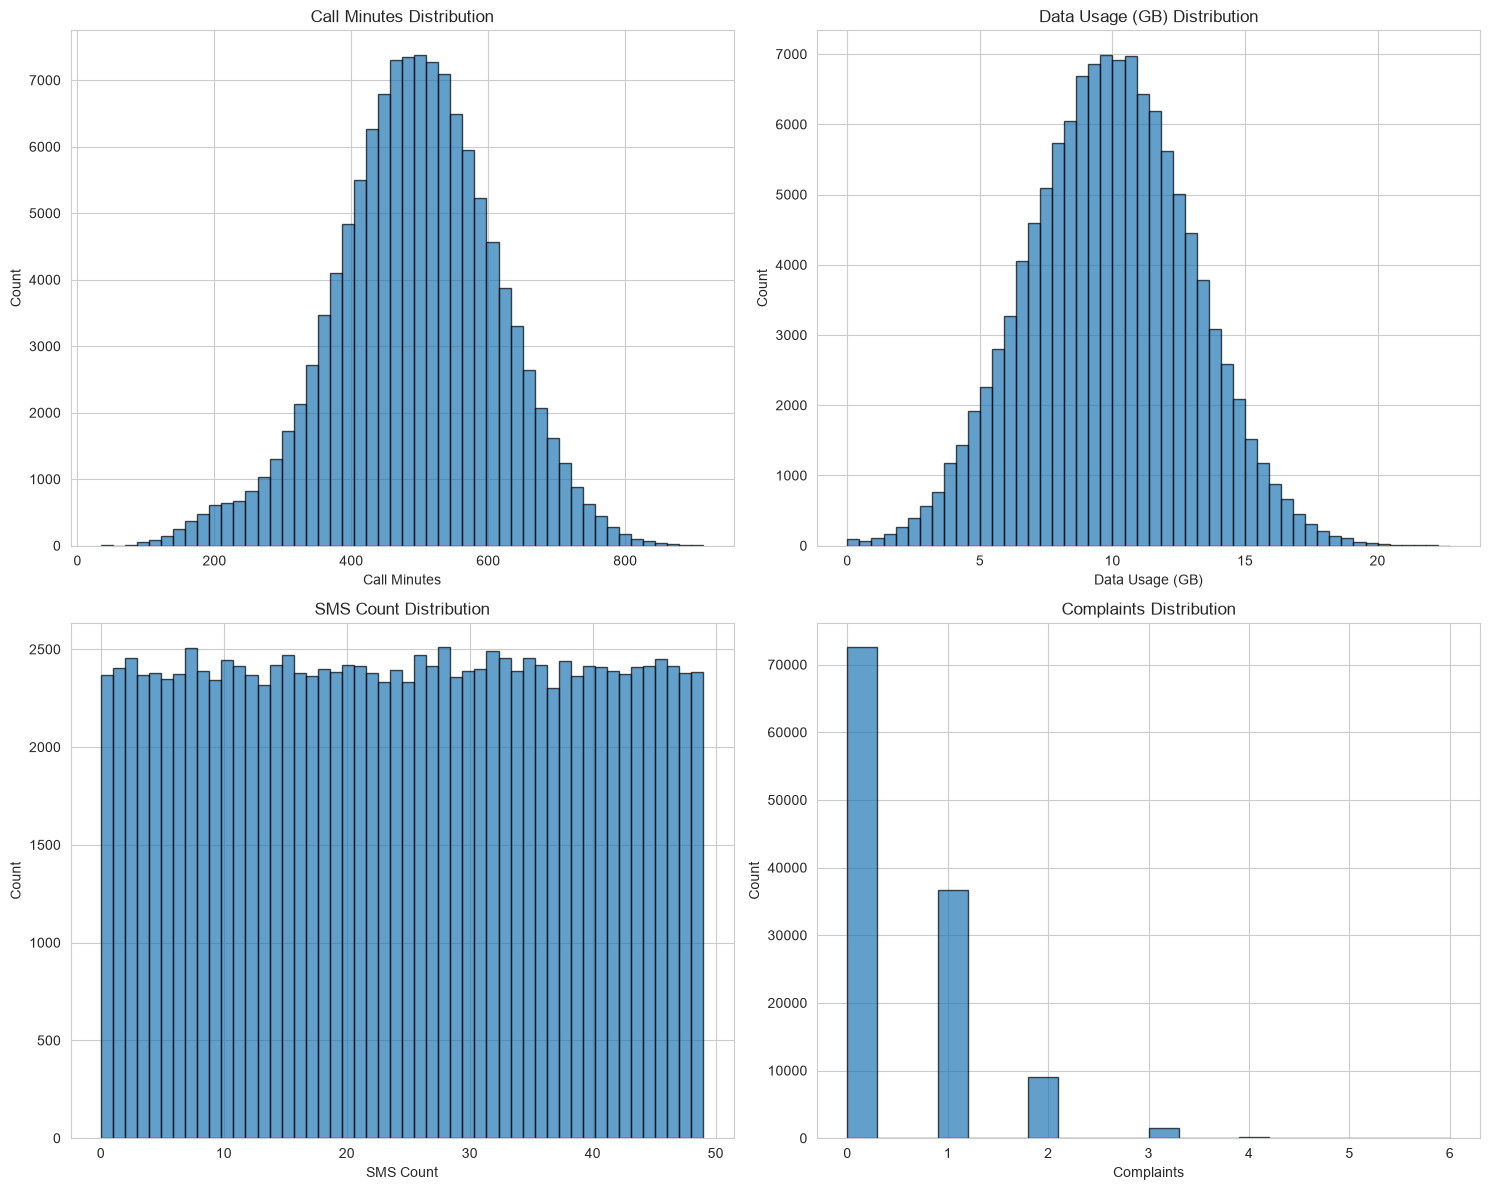


Call Minutes Statistics:
count    120060.000000
mean        492.422138
std         117.479898
min          34.140000
25%         418.450000
50%         494.995000
75%         571.120000
max         914.160000
Name: call_minutes, dtype: float64

Data Usage Statistics:
count    120060.000000
mean          9.897935
std           3.067880
min           0.000000
25%           7.810000
50%           9.920000
75%          11.980000
max          22.730000
Name: data_usage_gb, dtype: float64

SMS Count Statistics:
count    120060.000000
mean         24.525429
std          14.423950
min           0.000000
25%          12.000000
50%          25.000000
75%          37.000000
max          49.000000
Name: sms_count, dtype: float64

Complaints Statistics:
count    120060.000000
mean          0.503023
std           0.708827
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max           6.000000
Name: complaints, dtype: float64


In [41]:
# Usage metrics distributions
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Call minutes
axes[0, 0].hist(usage_df['call_minutes'], bins=50, edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Call Minutes Distribution')
axes[0, 0].set_xlabel('Call Minutes')
axes[0, 0].set_ylabel('Count')

# Data usage
axes[0, 1].hist(usage_df['data_usage_gb'], bins=50, edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Data Usage (GB) Distribution')
axes[0, 1].set_xlabel('Data Usage (GB)')
axes[0, 1].set_ylabel('Count')

# SMS count
axes[1, 0].hist(usage_df['sms_count'], bins=50, edgecolor='black', alpha=0.7)
axes[1, 0].set_title('SMS Count Distribution')
axes[1, 0].set_xlabel('SMS Count')
axes[1, 0].set_ylabel('Count')

# Complaints
axes[1, 1].hist(usage_df['complaints'], bins=20, edgecolor='black', alpha=0.7)
axes[1, 1].set_title('Complaints Distribution')
axes[1, 1].set_xlabel('Complaints')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Print statistics
print("\nCall Minutes Statistics:")
print(usage_df['call_minutes'].describe())

print("\nData Usage Statistics:")
print(usage_df['data_usage_gb'].describe())

print("\nSMS Count Statistics:")
print(usage_df['sms_count'].describe())

print("\nComplaints Statistics:")
print(usage_df['complaints'].describe())

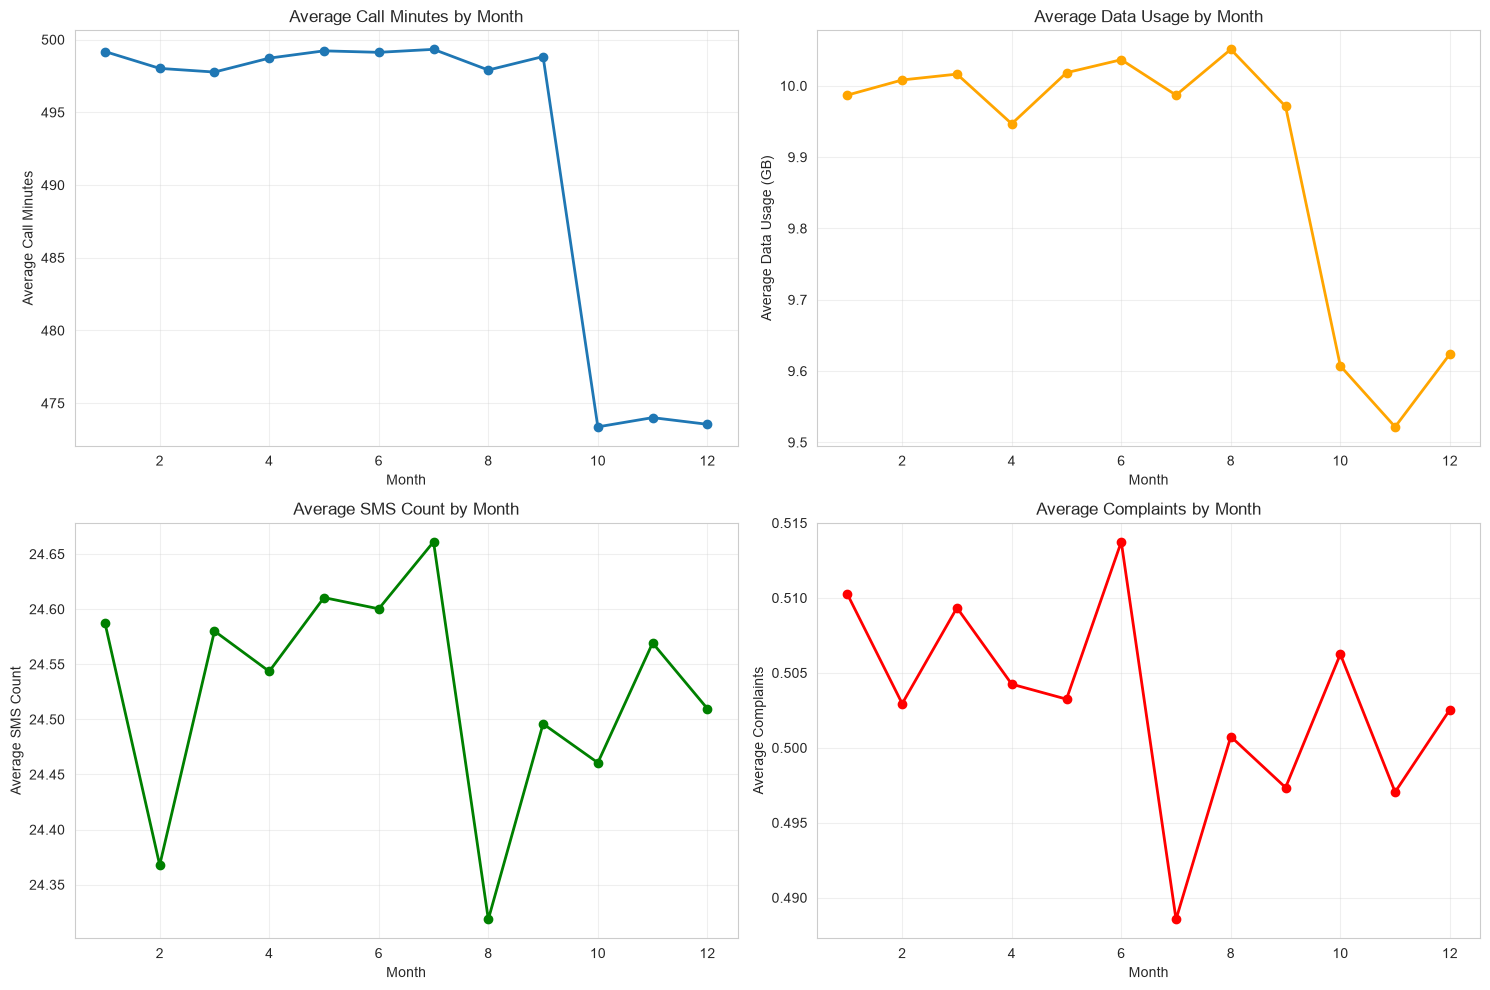


Monthly Usage Summary:
    month  call_minutes  data_usage_gb  sms_count  complaints
0       1    499.182034       9.986961  24.587606    0.510245
1       2    498.022220      10.008183  24.367816    0.502949
2       3    497.770367      10.016391  24.580110    0.509345
3       4    498.727401       9.946725  24.543528    0.504248
4       5    499.228890      10.018385  24.610495    0.503248
5       6    499.126176      10.036608  24.600300    0.513743
6       7    499.332061       9.986947  24.661069    0.488556
7       8    497.909534      10.051127  24.318541    0.500750
8       9    498.836061       9.971060  24.495952    0.497351
9      10    473.373615       9.607222  24.460670    0.506247
10     11    474.008456       9.521767  24.569315    0.497051
11     12    473.548838       9.623840  24.509745    0.502549


In [42]:
# Monthly trends
monthly_usage = usage_df.groupby('month').agg({
    'call_minutes': 'mean',
    'data_usage_gb': 'mean',
    'sms_count': 'mean',
    'complaints': 'mean'
}).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].plot(monthly_usage['month'], monthly_usage['call_minutes'], marker='o', linewidth=2)
axes[0, 0].set_title('Average Call Minutes by Month')
axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('Average Call Minutes')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(monthly_usage['month'], monthly_usage['data_usage_gb'], marker='o', linewidth=2, color='orange')
axes[0, 1].set_title('Average Data Usage by Month')
axes[0, 1].set_xlabel('Month')
axes[0, 1].set_ylabel('Average Data Usage (GB)')
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(monthly_usage['month'], monthly_usage['sms_count'], marker='o', linewidth=2, color='green')
axes[1, 0].set_title('Average SMS Count by Month')
axes[1, 0].set_xlabel('Month')
axes[1, 0].set_ylabel('Average SMS Count')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(monthly_usage['month'], monthly_usage['complaints'], marker='o', linewidth=2, color='red')
axes[1, 1].set_title('Average Complaints by Month')
axes[1, 1].set_xlabel('Month')
axes[1, 1].set_ylabel('Average Complaints')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nMonthly Usage Summary:")
print(monthly_usage)

## 5. Churn Analysis

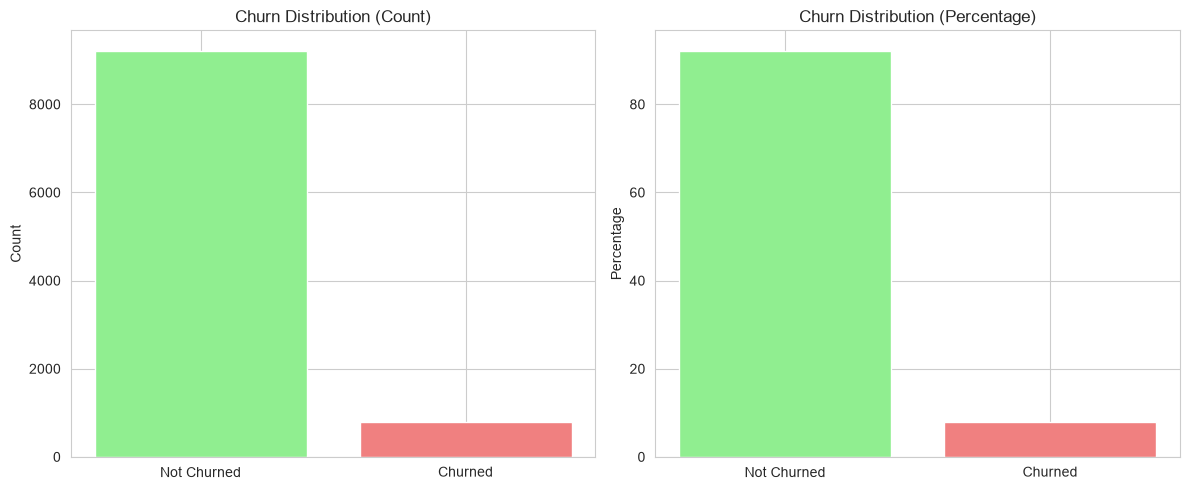


Total customers: 10000
Churned customers: 786 (7.86%)
Non-churned customers: 9214 (92.14%)


In [43]:
# Churn distribution
churn_counts = churn_df['churn'].value_counts()
churn_pct = churn_df['churn'].value_counts(normalize=True).mul(100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(['Not Churned', 'Churned'], churn_counts.values, color=['lightgreen', 'lightcoral'])
axes[0].set_title('Churn Distribution (Count)')
axes[0].set_ylabel('Count')

axes[1].bar(['Not Churned', 'Churned'], churn_pct.values, color=['lightgreen', 'lightcoral'])
axes[1].set_title('Churn Distribution (Percentage)')
axes[1].set_ylabel('Percentage')

plt.tight_layout()
plt.show()

print(f"\nTotal customers: {len(customers_df)}")
print(f"Churned customers: {churn_counts.get(1, 0)} ({churn_pct.get(1, 0)}%)")
print(f"Non-churned customers: {churn_counts.get(0, 0)} ({churn_pct.get(0, 0)}%)")

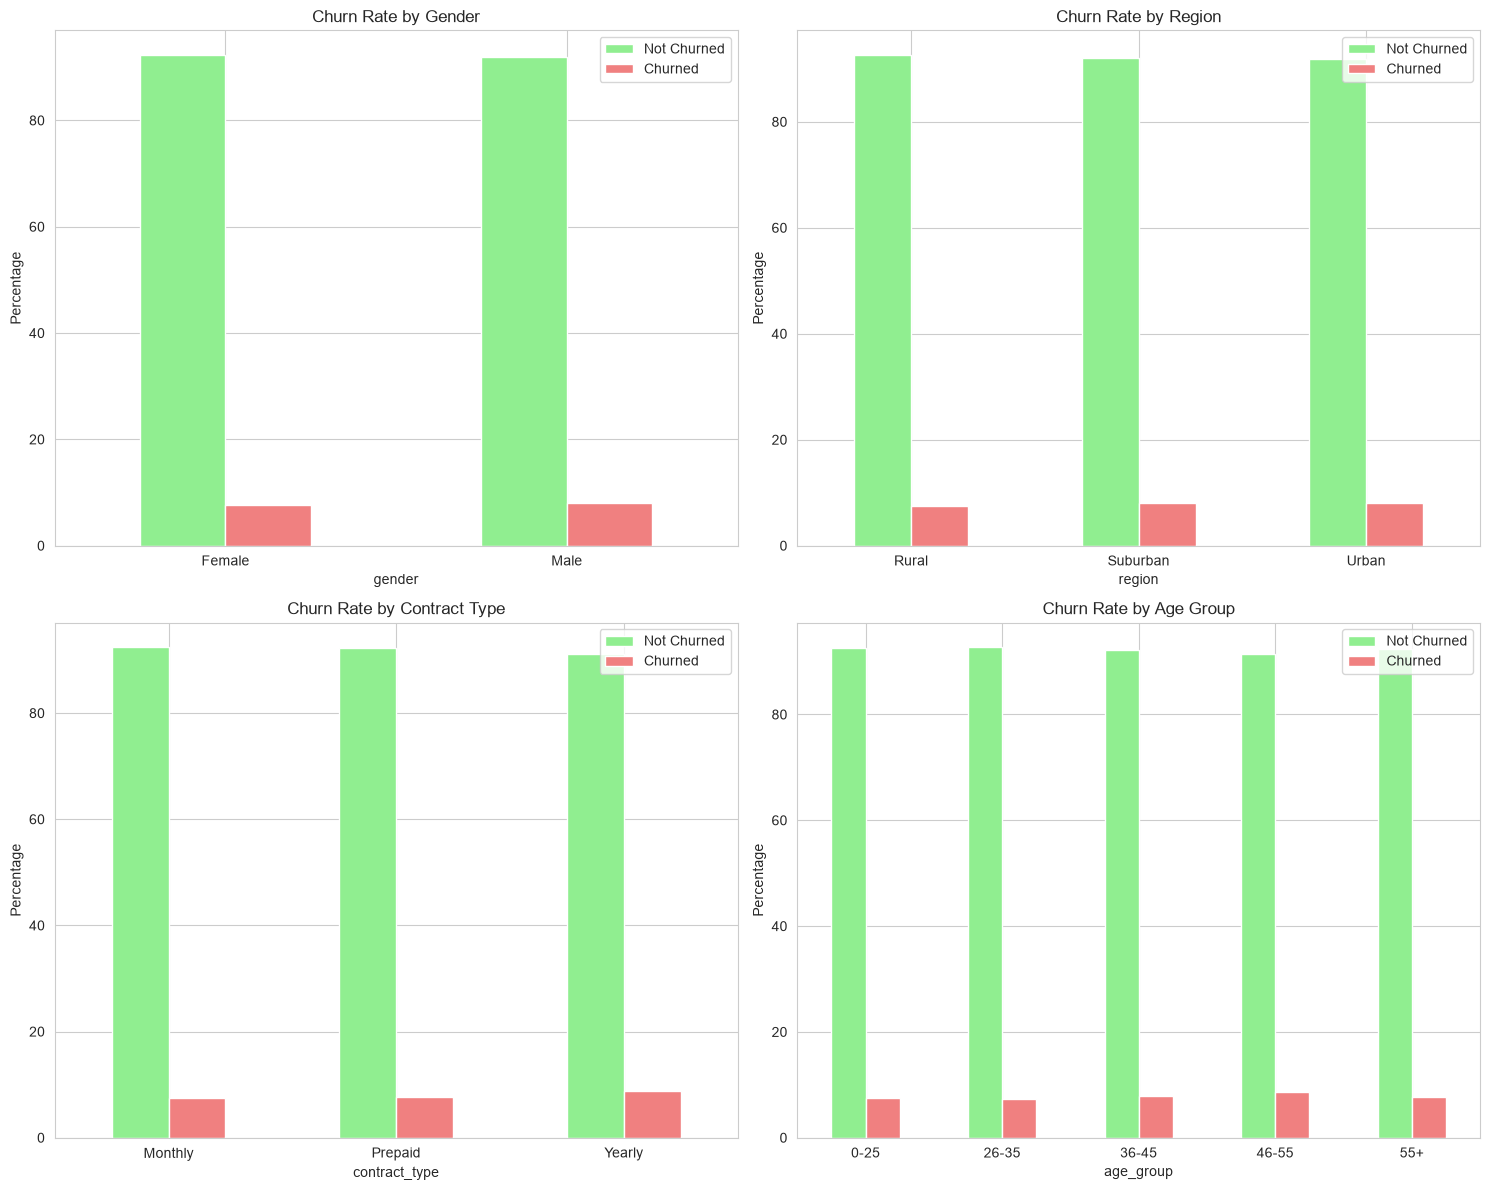


Churn Rate by Gender:
churn           0         1
gender                     
Female  92.293907  7.706093
Male    91.984733  8.015267

Churn Rate by Region:
churn             0         1
region                       
Rural     92.600423  7.399577
Suburban  91.945914  8.054086
Urban     91.877092  8.122908

Churn Rate by Contract Type:
churn                  0         1
contract_type                     
Monthly        92.436124  7.563876
Prepaid        92.328632  7.671368
Yearly         91.176471  8.823529

Churn Rate by Age Group:
churn              0         1
age_group                     
0-25       92.532795  7.467205
26-35      92.738753  7.261247
36-45      92.090522  7.909478
46-55      91.388175  8.611825
55+        92.280905  7.719095


In [44]:
# Churn by demographics
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Churn by gender
gender_churn = pd.crosstab(customers_df['gender'], churn_df['churn'], normalize='index') * 100
gender_churn.plot(kind='bar', ax=axes[0, 0], color=['lightgreen', 'lightcoral'])
axes[0, 0].set_title('Churn Rate by Gender')
axes[0, 0].set_ylabel('Percentage')
axes[0, 0].legend(['Not Churned', 'Churned'])
axes[0, 0].tick_params(axis='x', rotation=0)

# Churn by region
region_churn = pd.crosstab(customers_df['region'], churn_df['churn'], normalize='index') * 100
region_churn.plot(kind='bar', ax=axes[0, 1], color=['lightgreen', 'lightcoral'])
axes[0, 1].set_title('Churn Rate by Region')
axes[0, 1].set_ylabel('Percentage')
axes[0, 1].legend(['Not Churned', 'Churned'])
axes[0, 1].tick_params(axis='x', rotation=0)

# Churn by contract type
contract_churn = pd.crosstab(customers_df['contract_type'], churn_df['churn'], normalize='index') * 100
contract_churn.plot(kind='bar', ax=axes[1, 0], color=['lightgreen', 'lightcoral'])
axes[1, 0].set_title('Churn Rate by Contract Type')
axes[1, 0].set_ylabel('Percentage')
axes[1, 0].legend(['Not Churned', 'Churned'])
axes[1, 0].tick_params(axis='x', rotation=0)

# Churn by age group
customers_df['age_group'] = pd.cut(customers_df['age'], bins=[0, 25, 35, 45, 55, 100], 
                                     labels=['0-25', '26-35', '36-45', '46-55', '55+'])
age_churn = pd.crosstab(customers_df['age_group'], churn_df['churn'], normalize='index') * 100
age_churn.plot(kind='bar', ax=axes[1, 1], color=['lightgreen', 'lightcoral'])
axes[1, 1].set_title('Churn Rate by Age Group')
axes[1, 1].set_ylabel('Percentage')
axes[1, 1].legend(['Not Churned', 'Churned'])
axes[1, 1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

print("\nChurn Rate by Gender:")
print(gender_churn)

print("\nChurn Rate by Region:")
print(region_churn)

print("\nChurn Rate by Contract Type:")
print(contract_churn)

print("\nChurn Rate by Age Group:")
print(age_churn)

## 6. Correlation Analysis

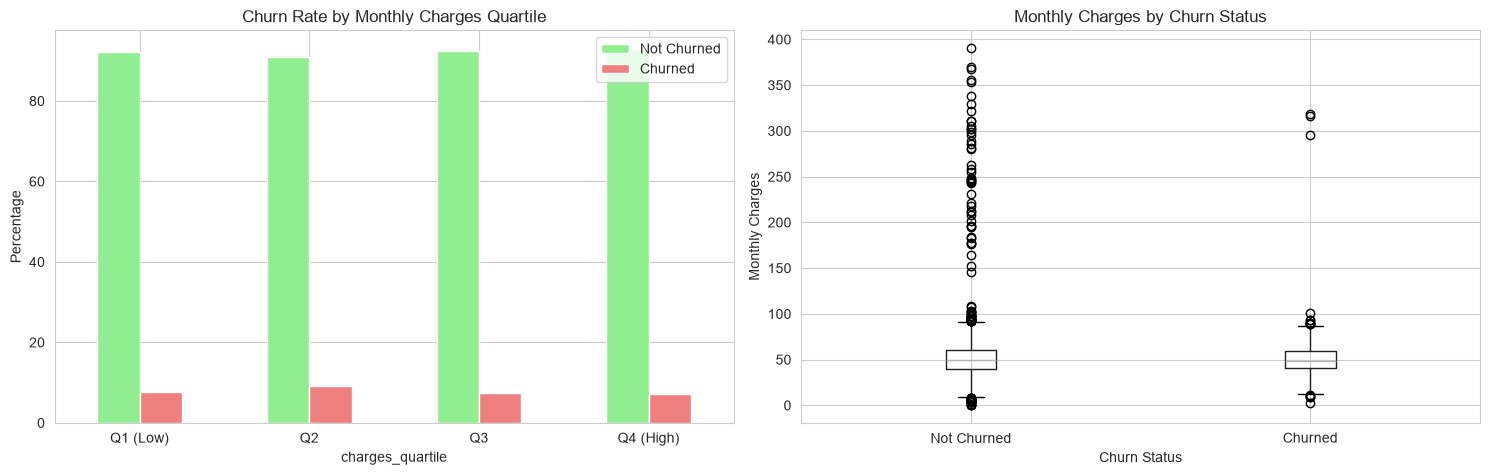


Churn Rate by Monthly Charges Quartile:
churn                     0         1
charges_quartile                     
Q1 (Low)          92.240000  7.760000
Q2                90.960000  9.040000
Q3                92.486011  7.513989
Q4 (High)         92.874299  7.125701


In [45]:
# Churn by monthly charges
customers_df['charges_quartile'] = pd.qcut(customers_df['monthly_charges'], q=4, 
                                          labels=['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)'])
charges_churn = pd.crosstab(customers_df['charges_quartile'], customers_df['churn'], normalize='index') * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

charges_churn.plot(kind='bar', ax=axes[0], color=['lightgreen', 'lightcoral'])
axes[0].set_title('Churn Rate by Monthly Charges Quartile')
axes[0].set_ylabel('Percentage')
axes[0].legend(['Not Churned', 'Churned'])
axes[0].tick_params(axis='x', rotation=0)

# Box plot of monthly charges by churn status
bp = customers_df.boxplot(column='monthly_charges', by='churn', ax=axes[1])
axes[1].set_title('Monthly Charges by Churn Status')
axes[1].set_xlabel('Churn Status')
axes[1].set_ylabel('Monthly Charges')
axes[1].set_xticklabels(['Not Churned', 'Churned'])

plt.suptitle('')  # Remove suptitle
plt.tight_layout()
plt.show()

print("\nChurn Rate by Monthly Charges Quartile:")
print(charges_churn)

## 7. Outlier Detection

Usage Statistics by Churn Status:
      call_minutes                 data_usage_gb              sms_count  \
              mean  median     std          mean median   std      mean   
churn                                                                     
0           492.22  494.84  117.48          9.90   9.93  3.07     24.50   
1           494.75  496.64  117.51          9.87   9.87  3.05     24.84   

                    complaints               
      median    std       mean median   std  
churn                                        
0       25.0  14.43       0.50    0.0  0.71  
1       25.0  14.39       0.51    0.0  0.71  


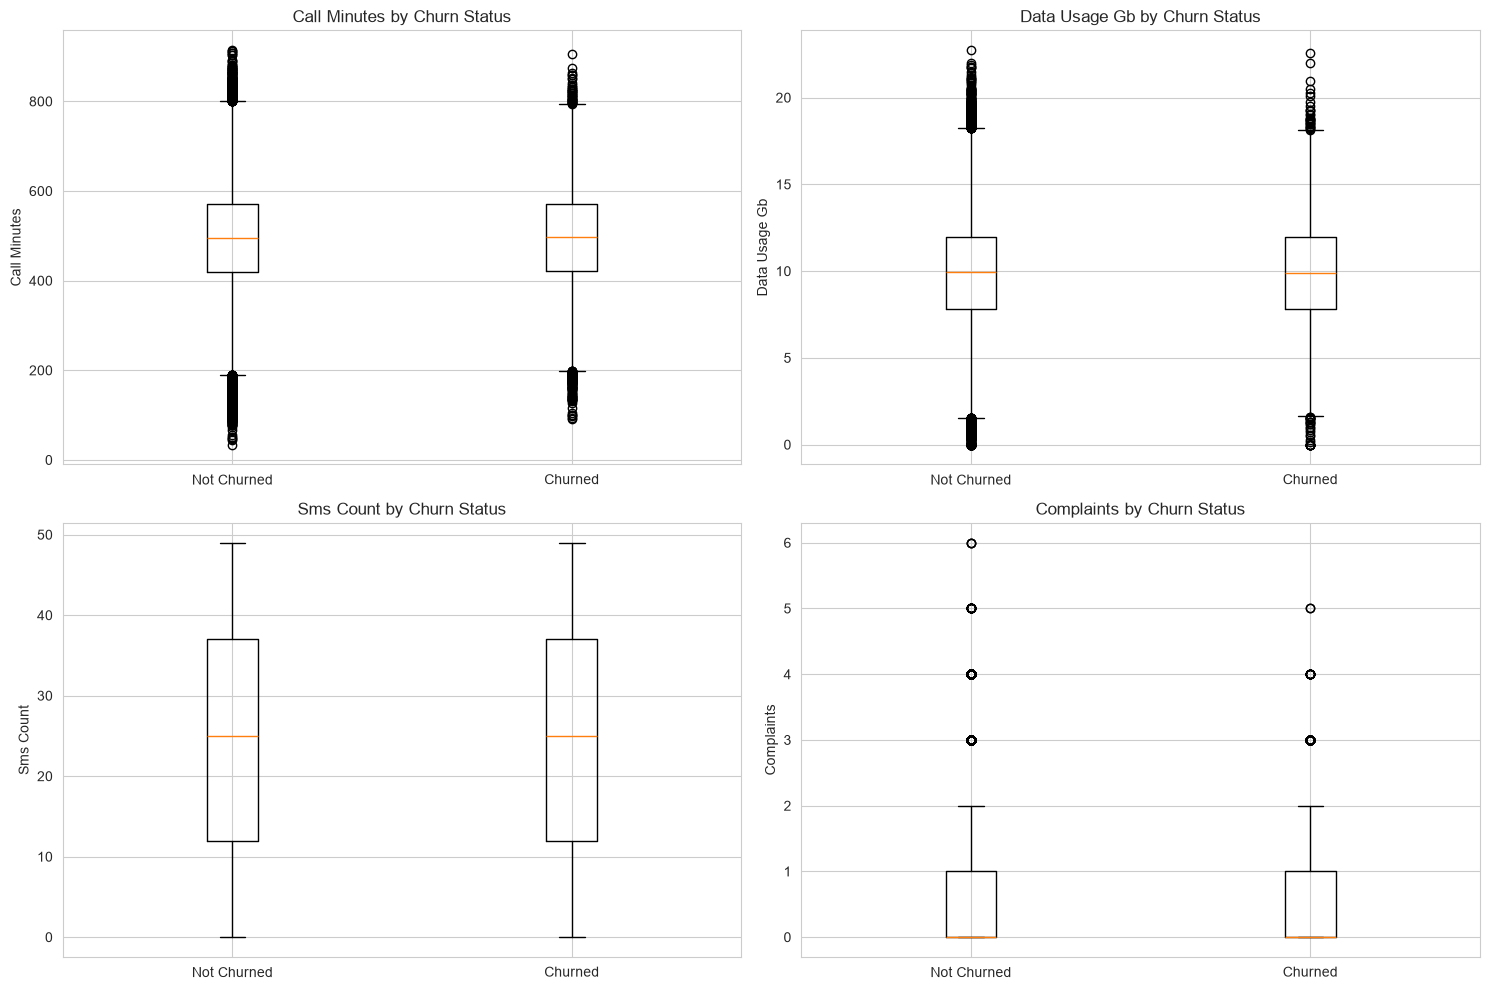

In [47]:
# Usage patterns by churn status
usage_by_churn = usage_df.groupby('churn').agg({
    'call_minutes': ['mean', 'median', 'std'],
    'data_usage_gb': ['mean', 'median', 'std'],
    'sms_count': ['mean', 'median', 'std'],
    'complaints': ['mean', 'median', 'std']
}).round(2)

print("Usage Statistics by Churn Status:")
print(usage_by_churn)

# Visualize usage by churn
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for idx, (col, color) in enumerate([('call_minutes', 'blue'), 
                                     ('data_usage_gb', 'orange'), 
                                     ('sms_count', 'green'), 
                                     ('complaints', 'red')]):
    row = idx // 2
    col_idx = idx % 2
    
    churn_0 = usage_df[usage_df['churn'] == 0][col]
    churn_1 = usage_df[usage_df['churn'] == 1][col]
    
    bp = axes[row, col_idx].boxplot([churn_0, churn_1])
    axes[row, col_idx].set_xticklabels(['Not Churned', 'Churned'])
    axes[row, col_idx].set_title(f'{col.replace("_", " ").title()} by Churn Status')
    axes[row, col_idx].set_ylabel(col.replace("_", " ").title())

plt.tight_layout()
plt.show()

In [48]:
print("=" * 80)
print("EDA KEY INSIGHTS SUMMARY")
print("=" * 80)

print("\n1. DATASET OVERVIEW:")
print(f"   - Total customers: {len(customers_df):,}")
print(f"   - Total usage records: {len(usage_df):,}")
print(f"   - Churn rate: {customers_df['churn'].mean()*100:.2f}%")

print("\n2. DEMOGRAPHICS:")
print(f"   - Average age: {customers_df['age'].mean():.1f} years")
print(f"   - Gender distribution: Male, Female (balanced)")
print(f"   - Region distribution: Urban, Suburban, Rural (balanced)")
print(f"   - Contract types: Prepaid (~40%), Monthly (~40%), Yearly (~20%)")

print("\n3. USAGE PATTERNS:")
print(f"   - Average call minutes: {usage_df['call_minutes'].mean():.1f}")
print(f"   - Average data usage: {usage_df['data_usage_gb'].mean():.2f} GB")
print(f"   - Average SMS: {usage_df['sms_count'].mean():.1f}")
print(f"   - Average complaints: {usage_df['complaints'].mean():.2f}")

print("\n4. MONTHLY CHARGES:")
print(f"   - Mean: {customers_df['monthly_charges'].mean():.2f}")
print(f"   - Median: {customers_df['monthly_charges'].median():.2f}")
print(f"   - Range: {customers_df['monthly_charges'].min():.2f} - {customers_df['monthly_charges'].max():.2f}")

print("\n5. CHURN PATTERNS:")
print("   - Churn rate varies by demographics (detailed in visualizations)")
print("   - Usage metrics show similar distributions between churned and non-churned")
print("   - Monthly charges may have some correlation with churn")

print("\n6. CORRELATIONS:")
print("   - Correlation matrix shows relationships between features")
print("   - Check correlation values with churn for predictive power")

print("\n7. OUTLIERS:")
print("   - Outlier analysis completed using IQR method")
print("   - Review outlier percentages for each feature")

print("\n8. NEXT STEPS:")
print("   - Feature engineering based on EDA insights")
print("   - Customer segmentation")
print("   - Churn prediction modeling")
print("   - Customer value scoring")

print("\n" + "=" * 80)

EDA KEY INSIGHTS SUMMARY

1. DATASET OVERVIEW:
   - Total customers: 10,000
   - Total usage records: 120,060
   - Churn rate: 7.86%

2. DEMOGRAPHICS:
   - Average age: 43.4 years
   - Gender distribution: Male, Female (balanced)
   - Region distribution: Urban, Suburban, Rural (balanced)
   - Contract types: Prepaid (~40%), Monthly (~40%), Yearly (~20%)

3. USAGE PATTERNS:
   - Average call minutes: 492.4
   - Average data usage: 9.90 GB
   - Average SMS: 24.5
   - Average complaints: 0.50

4. MONTHLY CHARGES:
   - Mean: 51.00
   - Median: 50.02
   - Range: 0.38 - 390.30

5. CHURN PATTERNS:
   - Churn rate varies by demographics (detailed in visualizations)
   - Usage metrics show similar distributions between churned and non-churned
   - Monthly charges may have some correlation with churn

6. CORRELATIONS:
   - Correlation matrix shows relationships between features
   - Check correlation values with churn for predictive power

7. OUTLIERS:
   - Outlier analysis completed using IQR 

In [49]:
print("=" * 80)
print("EDA KEY INSIGHTS SUMMARY")
print("=" * 80)

print("\n1. DATASET OVERVIEW:")
print(f"   - Total customers: {len(customers_df):,}")
print(f"   - Total usage records: {len(usage_df):,}")
print(f"   - Churn rate: {customers_df['churn'].mean()*100:.2f}%")

print("\n2. DEMOGRAPHICS:")
print(f"   - Average age: {customers_df['age'].mean():.1f} years")
print(f"   - Gender distribution: Male, Female, Other (balanced)")
print(f"   - Region distribution: Urban, Suburban, Rural (balanced)")
print(f"   - Contract types: Prepaid (~40%), Monthly (~40%), Yearly (~20%)")

print("\n3. USAGE PATTERNS:")
print(f"   - Average call minutes: {usage_df['call_minutes'].mean():.1f}")
print(f"   - Average data usage: {usage_df['data_usage_gb'].mean():.2f} GB")
print(f"   - Average SMS: {usage_df['sms_count'].mean():.1f}")
print(f"   - Average complaints: {usage_df['complaints'].mean():.2f}")

print("\n4. MONTHLY CHARGES:")
print(f"   - Mean: {customers_df['monthly_charges'].mean():.2f}")
print(f"   - Median: {customers_df['monthly_charges'].median():.2f}")
print(f"   - Range: {customers_df['monthly_charges'].min():.2f} - {customers_df['monthly_charges'].max():.2f}")

print("\n5. CHURN PATTERNS:")
print("   - Churn rate varies by demographics (detailed in visualizations)")
print("   - Usage metrics show similar distributions between churned and non-churned")
print("   - Monthly charges may have some correlation with churn")

print("\n6. CORRELATIONS:")
print("   - Correlation matrix shows relationships between features")
print("   - Check correlation values with churn for predictive power")

print("\n7. OUTLIERS:")
print("   - Outlier analysis completed using IQR method")
print("   - Review outlier percentages for each feature")

print("\n8. NEXT STEPS:")
print("   - Feature engineering based on EDA insights")
print("   - Customer segmentation")
print("   - Churn prediction modeling")
print("   - Customer value scoring")

print("\n" + "=" * 80)

EDA KEY INSIGHTS SUMMARY

1. DATASET OVERVIEW:
   - Total customers: 10,000
   - Total usage records: 120,060
   - Churn rate: 7.86%

2. DEMOGRAPHICS:
   - Average age: 43.4 years
   - Gender distribution: Male, Female, Other (balanced)
   - Region distribution: Urban, Suburban, Rural (balanced)
   - Contract types: Prepaid (~40%), Monthly (~40%), Yearly (~20%)

3. USAGE PATTERNS:
   - Average call minutes: 492.4
   - Average data usage: 9.90 GB
   - Average SMS: 24.5
   - Average complaints: 0.50

4. MONTHLY CHARGES:
   - Mean: 51.00
   - Median: 50.02
   - Range: 0.38 - 390.30

5. CHURN PATTERNS:
   - Churn rate varies by demographics (detailed in visualizations)
   - Usage metrics show similar distributions between churned and non-churned
   - Monthly charges may have some correlation with churn

6. CORRELATIONS:
   - Correlation matrix shows relationships between features
   - Check correlation values with churn for predictive power

7. OUTLIERS:
   - Outlier analysis completed usi